# Oil and US inflation: final feasibility analysis
This extends the initial POC rather than replacing it. We verify monthly seasonally adjusted CPI,
compare yearly versus monthly outcomes, fit a three-variable Bayesian model with AR(1) residuals,
validate recovery, check posterior sampling and prediction, and assess whether the causal plan is defensible.
All results are exploratory model development using revised snapshots, not preregistered confirmation.
Sources: [BLS CPI via FRED](https://fred.stlouisfed.org/series/CPIAUCSL),
[Brent](https://fred.stlouisfed.org/series/MCOILBRENTEU),
[Dallas Fed IGREA](https://www.dallasfed.org/research/igrea).

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm, rankdata
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf
ROOT=Path.cwd()
if not (ROOT/'data/raw').exists(): ROOT=ROOT.parent
OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(10,4),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def plot_save(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),bbox_inches='tight'); plt.show(); plt.close()
oil=pd.read_csv(ROOT/'data/raw/brent_direct.csv',parse_dates=[0]);oil.columns=['date','oil']
cpi=pd.read_csv(ROOT/'data/raw/us_cpi_seasonally_adjusted.csv',parse_dates=[0]);cpi.columns=['date','cpi']
dem=pd.read_csv(ROOT/'data/raw/igrea.csv',parse_dates=[0]);dem.columns=['date','demand']
for frame in [oil,cpi,dem]:assert not frame.date.duplicated().any()
d=pd.DataFrame({'date':pd.date_range('1999-01-01','2024-12-01',freq='MS')})
for frame in [oil,cpi,dem]:d=d.merge(frame,on='date',how='left',validate='one_to_one')
d['oil_pct']=d.oil.pct_change(fill_method=None)*100
d['monthly']=d.cpi.pct_change(fill_method=None)*100
d['yearly']=d.cpi.pct_change(12,fill_method=None)*100
d['T']=d.oil_pct.shift(1)/10;d['C']=d.demand.shift(2)/100
d['last_monthly']=d.monthly.shift(1)
d=d[d.date.ge('2000-01-01')].reset_index(drop=True)
assert len(d)==300 and d[['monthly','yearly','T','C']].notna().all().all()
d.to_csv(ROOT/'data/processed/us_monthly.csv',index=False)
print('300 unique, complete monthly observations; no interpolation.')
print(d[['monthly','yearly','T','C']].describe().round(3).to_string())
print('Treatment/prior demand correlation:',round(d['T'].corr(d.C),3))

300 unique, complete monthly observations; no interpolation.
       monthly   yearly        T        C
count  300.000  300.000  300.000  300.000
mean     0.211    2.579    0.090    0.075
std      0.306    1.763    1.011    0.681
min     -1.771   -1.959   -4.258   -1.625
25%      0.055    1.608   -0.462   -0.412
50%      0.217    2.305    0.197   -0.014
75%      0.351    3.339    0.709    0.498
max      1.377    8.979    5.985    1.886
Treatment/prior demand correlation: 0.067


## Why change the outcome?
Monthly CPI inflation is 100(CPI_t/CPI_(t-1)−1), in monthly percentage points, not annualized.
It avoids the mechanically overlapping 12-month windows in yearly inflation, but answers a different question.
Treatment is the prior month's oil percentage change divided by 10; confounder is IGREA from two months prior divided by 100.
These are fixed unit conversions, not fitted standardization. DAG: C→T, C→Y, T→Y.
The proxy and DAG remain contestable; AR residuals model dependence, not additional causal adjustment.

outcome   beta  HAC_low  HAC_high  residual_lag1
 yearly 0.1201  -0.0660    0.3062         0.9556
monthly 0.1460   0.0883    0.2037         0.2257


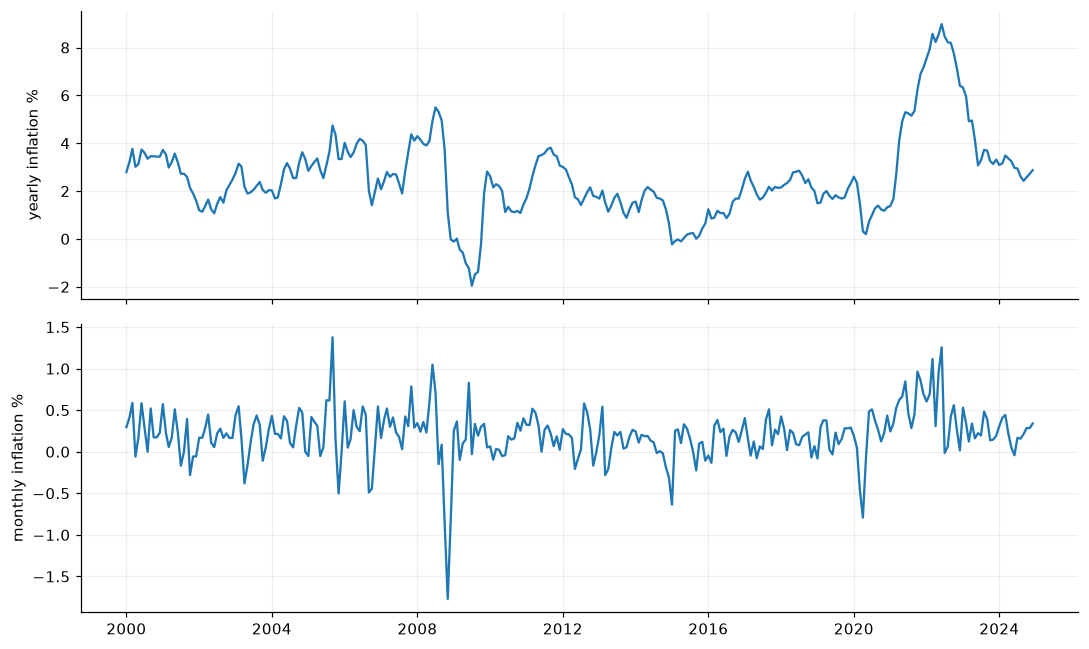

In [2]:
def Xmat(g,adj=True):return np.column_stack([np.ones(len(g)),g['T'],g['C']]) if adj else np.column_stack([np.ones(len(g)),g['T']])
screen=[]
for outcome in ['yearly','monthly']:
    fit=sm.OLS(d[outcome],Xmat(d)).fit(cov_type='HAC',cov_kwds={'maxlags':12})
    screen.append({'outcome':outcome,'beta':np.asarray(fit.params)[1],'HAC_low':np.asarray(fit.conf_int())[1,0],
                  'HAC_high':np.asarray(fit.conf_int())[1,1],'residual_lag1':pd.Series(fit.resid).autocorr()})
screen=pd.DataFrame(screen);print(screen.round(4).to_string(index=False));screen.to_csv(OUT/'outcome_comparison.csv',index=False)
fig,axs=plt.subplots(2,1,figsize=(10,6),sharex=True)
for ax,col in zip(axs,['yearly','monthly']):ax.plot(d.date,d[col]);ax.set_ylabel(col+' inflation %');ax.grid(alpha=.2)
plot_save('outcome_comparison')

## Fully specified Bayesian model with dependent errors
Y_t = α + β T_t + γ C_t + u_t; u_t = φ u_(t−1) + ε_t; ε_t ~ Normal(0,σ²).
Initial u_0 ~ Normal(0,σ²/(1−φ²)); |φ|<1. The unadjusted comparison omits γC.
Priors are independent: α~N(0,0.5²), β~N(0,0.3²), γ~N(0,0.5²), σ~HalfNormal(0.5), φ~Uniform(−1,1).
β is monthly inflation percentage points per 10-percentage-point oil change. These conservative,
zero-centered working priors allow either sign; the independent Fed mechanism paper motivates a possible
positive effect but does not calibrate this different estimand. Prior scale justification is provisional.
We show prior prediction and vary slope priors rather than claim that a predictive check validates a prior.

Four random-walk Metropolis chains sample b, log σ, atanh φ. MAP curvature provides a fixed proposal
shape, warmup adapts only the scalar step size, then sampling freezes it. All Jacobians are included.
The exact Gaussian AR(1) likelihood includes the stationary initial observation. No thinning.

Prior predictive central 95%: [-2.148  2.144] monthly percentage points


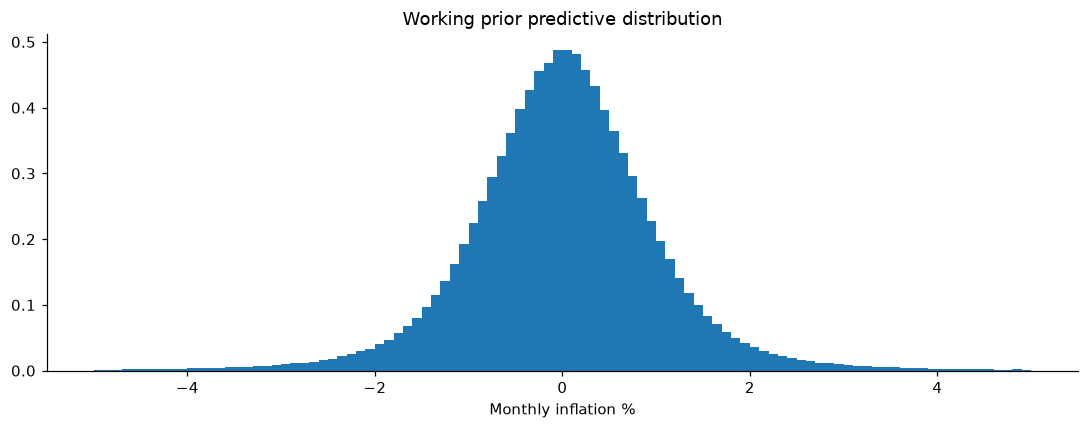

Acceptance: [0.257 0.245 0.268 0.244]
parameter   mean  lower95  upper95  rank_split_Rhat  bulk_ESS  tail_ESS  mean_MCSE_approx
    alpha 0.1992   0.1532   0.2458           1.0009 2196.9012 3616.5790            0.0005
     beta 0.0945   0.0602   0.1284           1.0020 2300.6558 3550.1304            0.0004
    gamma 0.0412  -0.0254   0.1034           1.0015 2169.6817 3230.2711            0.0007
    sigma 0.2568   0.2361   0.2791           1.0028 2296.2021 3825.0936            0.0002
      phi 0.3426   0.2105   0.4713           1.0026 2498.0747 3389.2946            0.0013


Unadjusted:
parameter   mean  lower95  upper95  rank_split_Rhat  bulk_ESS  tail_ESS  mean_MCSE_approx
    alpha 0.2025   0.1558   0.2477           1.0020 2782.6947 3898.9763            0.0004
     beta 0.0936   0.0611   0.1269           1.0024 2647.3646 4164.3469            0.0003
    sigma 0.2567   0.2375   0.2781           1.0006 3004.8077 4513.2088            0.0002
      phi 0.3554   0.2310   0.4746           1.0007 2536.9393 3428.2347            0.0013


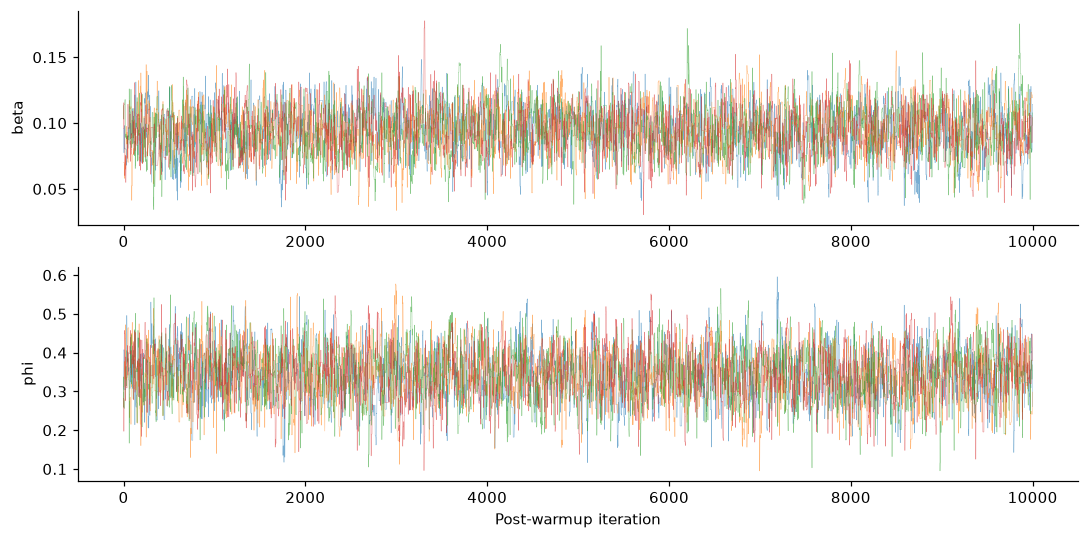

In [3]:
def target_factory(X,y):
    p=X.shape[1];scales=np.array([.5,.3,.5][:p]);n=len(y)
    def logp(z):
        b=z[:p];ls=z[p];eta=z[p+1]
        if abs(ls)>15 or abs(eta)>8:return -np.inf
        sigma=np.exp(ls);phi=np.tanh(eta);r=y-X@b
        ss=(1-phi**2)*r[0]**2+np.sum((r[1:]-phi*r[:-1])**2)
        return (-n*ls+.5*np.log1p(-phi**2)-.5*ss/sigma**2
                -.5*np.sum((b/scales)**2)-.5*(sigma/.5)**2+ls+np.log1p(-phi**2))
    return logp

def sample_model(X,y,seed=22,warm=3500,keep=10000):
    p=X.shape[1];logp=target_factory(X,y)
    b=np.linalg.lstsq(X,y,rcond=None)[0];res=y-X@b
    phi=np.clip(pd.Series(res).autocorr(),-.9,.9)
    start=np.r_[b,np.log(max(np.std(res[1:]-phi*res[:-1]),.03)),np.arctanh(phi)]
    opt=minimize(lambda z:-logp(z),start,method='BFGS',options={'gtol':1e-7})
    mode=opt.x;q=len(mode);h=1e-4
    H=np.empty((q,q));f=lambda z:-logp(z)
    for i in range(q):
        ei=np.eye(q)[i]*h
        for j in range(q):
            ej=np.eye(q)[j]*h
            H[i,j]=(f(mode+ei+ej)-f(mode+ei-ej)-f(mode-ei+ej)+f(mode-ei-ej))/(4*h*h)
    ev,U=np.linalg.eigh((H+H.T)/2);cov=(U*(1/np.maximum(ev,1e-3)))@U.T;L=np.linalg.cholesky(cov)
    chains=[];accept=[]
    for chain in range(4):
        rng=np.random.default_rng(seed+chain*100);z=mode+L@rng.normal(size=q)*2;lp=logp(z)
        step=2.38/np.sqrt(q);block=0;accepted=0;draw=[]
        for k in range(warm+keep):
            prop=z+step*(L@rng.normal(size=q));v=logp(prop)
            if np.log(rng.uniform())<v-lp:z=prop;lp=v;block+=1;accepted+=int(k>=warm)
            if k<warm and (k+1)%100==0:step*=np.exp(np.clip(block/100-.25,-.2,.2));block=0
            if k>=warm:draw.append(z.copy())
        chains.append(draw);accept.append(accepted/keep)
    chains=np.array(chains);chains[:,:,p]=np.exp(chains[:,:,p]);chains[:,:,p+1]=np.tanh(chains[:,:,p+1])
    return chains,accept

def diagnostics(chains,names):
    # Split-chain rank normalized/folded R-hat; bulk ESS via paired initial-positive autocorrelation sums.
    m,n,p=chains.shape;split=np.concatenate([chains[:,:n//2],chains[:,n//2:]],axis=0)
    def rhat(a):
        ns=a.shape[1];W=np.var(a,axis=1,ddof=1).mean();B=ns*np.var(a.mean(axis=1),ddof=1)
        return np.sqrt(((ns-1)/ns*W+B/ns)/W)
    def ess(a):
        ns=a.shape[1];W=np.var(a,axis=1,ddof=1).mean();vp=(ns-1)/ns*W+np.var(a.mean(axis=1),ddof=1)
        rho=1-(W-np.mean([acf(v,nlags=min(2000,ns-1),fft=True)*np.var(v,ddof=1) for v in a],axis=0))/vp
        pairs=[]
        for j in range(0,len(rho)-1,2):
            pair=rho[j]+rho[j+1]
            if pair<0:break
            pairs.append(min(pair,pairs[-1]) if pairs else pair)
        return min(a.size,a.size/max(-1+2*np.sum(pairs),1))
    rows=[]
    for j,name in enumerate(names):
        a=split[:,:,j];z=norm.ppf((rankdata(a).reshape(a.shape)-.375)/(a.size+.25))
        folded=np.abs(a-np.median(a));zf=norm.ppf((rankdata(folded).reshape(a.shape)-.375)/(a.size+.25))
        lo,hi=np.quantile(a,[.05,.95]);bulk=ess(z);tail=min(ess((a<=lo).astype(float)),ess((a>=hi).astype(float)))
        rows.append({'parameter':name,'mean':a.mean(),'lower95':np.quantile(a,.025),'upper95':np.quantile(a,.975),
                     'rank_split_Rhat':max(rhat(z),rhat(zf)),'bulk_ESS':bulk,'tail_ESS':tail,
                     'mean_MCSE_approx':a.std()/np.sqrt(bulk)})
    return pd.DataFrame(rows)

rng=np.random.default_rng(50);nprior=3000
bp=rng.normal(size=(nprior,3))*[.5,.3,.5];sp=np.abs(rng.normal(0,.5,nprior));phip=rng.uniform(-1,1,nprior)
prior_res=np.empty((nprior,300));prior_res[:,0]=rng.normal(size=nprior)*sp/np.sqrt(1-phip**2)
for t in range(1,300):prior_res[:,t]=phip*prior_res[:,t-1]+rng.normal(size=nprior)*sp
prior_pred=bp@Xmat(d).T+prior_res
print('Prior predictive central 95%:',np.quantile(prior_pred,[.025,.975]).round(3),'monthly percentage points')
plt.hist(prior_pred.ravel(),bins=100,range=(-5,5),density=True);plt.xlabel('Monthly inflation %');plt.title('Working prior predictive distribution');plot_save('prior_predictive')
chains,accept=sample_model(Xmat(d),d.monthly.to_numpy())
diag=diagnostics(chains,['alpha','beta','gamma','sigma','phi']);print('Acceptance:',np.round(accept,3));print(diag.round(4).to_string(index=False))
diag.to_csv(OUT/'posterior_diagnostics.csv',index=False);np.savez_compressed(OUT/'posterior_draws.npz',adjusted=chains)
unadj,acc_u=sample_model(Xmat(d,False),d.monthly.to_numpy(),seed=42)
diag_u=diagnostics(unadj,['alpha','beta','sigma','phi']);print('Unadjusted:');print(diag_u.round(4).to_string(index=False));diag_u.to_csv(OUT/'unadjusted_diagnostics.csv',index=False)
fig,axs=plt.subplots(2,1,figsize=(10,5))
for c in range(4):axs[0].plot(chains[c,:,1],lw=.3,alpha=.6);axs[1].plot(chains[c,:,-1],lw=.3,alpha=.6)
axs[0].set_ylabel('beta');axs[1].set_ylabel('phi');axs[1].set_xlabel('Post-warmup iteration');plot_save('mcmc_traces')

## Known-parameter recovery with confounding AND serial dependence
Synthetic data are separate. This checks implementation under its own assumptions and cannot establish
exchangeability for observed oil prices. True β=.15, γ=.25, φ=.4, σ=.15; prior demand drives both T and Y.

In [4]:
rng=np.random.default_rng(81);N=300;C=np.zeros(N)
for i in range(1,N):C[i]=.6*C[i-1]+rng.normal(0,.5)
T=.8*C+rng.normal(0,.7,N);Xs=np.column_stack([np.ones(N),T,C]);u=np.empty(N);u[0]=rng.normal(0,.15/np.sqrt(1-.4**2))
for i in range(1,N):u[i]=.4*u[i-1]+rng.normal(0,.15)
ys=Xs@np.array([.2,.15,.25])+u
sim,acc_s=sample_model(Xs,ys,seed=71)
simdiag=diagnostics(sim,['alpha','beta','gamma','sigma','phi']);simdiag['truth']=[.2,.15,.25,.15,.4]
print(simdiag.round(4).to_string(index=False));simdiag.to_csv(OUT/'simulation_recovery.csv',index=False)
sim_u,acc_su=sample_model(Xs[:,:2],ys,seed=171)
simudiag=diagnostics(sim_u,['alpha','beta','sigma','phi']);simudiag.to_csv(OUT/'simulation_unadjusted.csv',index=False)
print('Omitted-confounder simulated beta:',simudiag.loc[simudiag.parameter.eq('beta'),['mean','lower95','upper95']].round(4).to_string(index=False))

parameter   mean  lower95  upper95  rank_split_Rhat  bulk_ESS  tail_ESS  mean_MCSE_approx  truth
    alpha 0.2078   0.1780   0.2380           1.0029 2385.3738 3992.5074            0.0003   0.20
     beta 0.1498   0.1275   0.1713           1.0016 2259.9768 3462.2305            0.0002   0.15
    gamma 0.2368   0.2008   0.2740           1.0021 2490.8927 3734.6760            0.0004   0.25
    sigma 0.1523   0.1409   0.1654           1.0021 2290.1445 3084.9085            0.0001   0.15
      phi 0.4164   0.3093   0.5201           1.0020 2302.8380 3574.9361            0.0011   0.40


Omitted-confounder simulated beta:   mean  lower95  upper95
0.2001    0.176   0.2251


## Posterior predictive checks and robustness
Unconditional replications check dependence and distribution; conditional innovations check remaining
serial structure. Intervals shown are pointwise. AR(1) is a testable approximation, not a guaranteed cure.

Innovation Ljung-Box (exploratory plug-in diagnostic):


      lb_stat  lb_pvalue
6    8.724767   0.189659
12  30.331516   0.002489


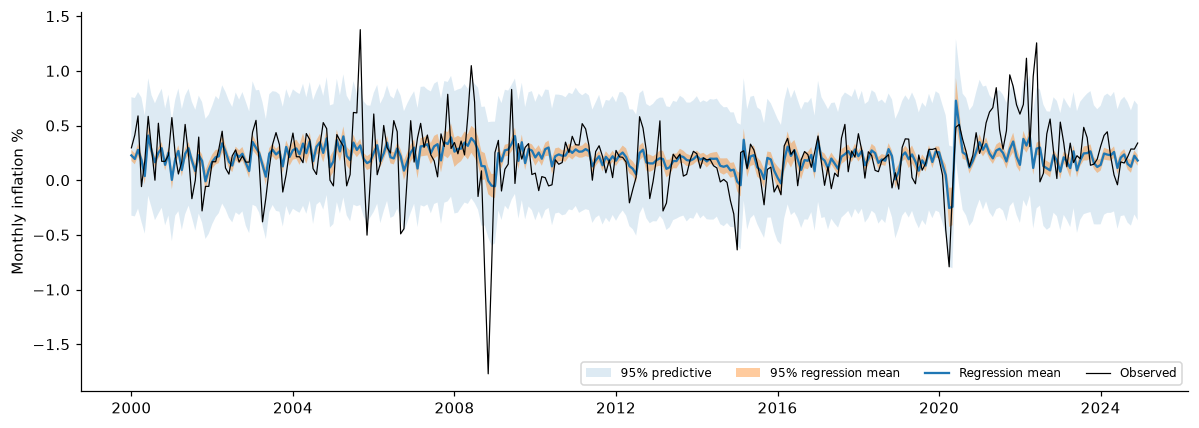

statistic  observed  rep_lower95  rep_upper95  fraction_rep_ge_observed
     lag1    0.4776       0.1787       0.4893                     0.037
  maximum    1.3768       0.8638       1.3747                     0.024
  minimum   -1.7705      -0.9518      -0.4302                     1.000
      std    0.3057       0.2581       0.3330                     0.238
                  sample   n   beta  HAC_low  HAC_high
                     all 300 0.1460   0.0883    0.2037
               2000-2019 240 0.1776   0.1039    0.2513
               2020-2024  60 0.0912   0.0652    0.1173
       exclude 2020-2022 264 0.1682   0.0951    0.2413
exclude oil changes >30% 296 0.1653   0.0965    0.2340
 beta_prior_sd  beta_mean  lower95  upper95  importance_ESS
          0.15     0.0935   0.0591   0.1277      39878.6639
          0.30     0.0945   0.0602   0.1284      40000.0000
          0.60     0.0947   0.0603   0.1286      39992.0965


In [5]:
flat=chains.reshape(-1,5);rng=np.random.default_rng(70);draw=flat[rng.choice(len(flat),2000,replace=False)]
mu=draw[:,:3]@Xmat(d).T;rep=np.empty_like(mu);r=np.empty_like(mu)
r[:,0]=rng.normal(size=len(draw))*draw[:,3]/np.sqrt(1-draw[:,4]**2)
for t in range(1,300):r[:,t]=draw[:,4]*r[:,t-1]+rng.normal(size=len(draw))*draw[:,3]
rep=mu+r;mean=flat.mean(axis=0);res=d.monthly.to_numpy()-Xmat(d)@mean[:3];innov=res[1:]-mean[4]*res[:-1]
lb=acorr_ljungbox(innov,lags=[6,12],return_df=True);print('Innovation Ljung-Box (exploratory plug-in diagnostic):');print(lb.to_string())
lb.to_csv(OUT/'innovation_ljung_box.csv')
fig,ax=plt.subplots(figsize=(11,4));ax.fill_between(d.date,*np.quantile(rep,[.025,.975],axis=0),alpha=.15,label='95% predictive')
ax.fill_between(d.date,*np.quantile(mu,[.025,.975],axis=0),alpha=.4,label='95% regression mean')
ax.plot(d.date,mu.mean(axis=0),label='Regression mean');ax.plot(d.date,d.monthly,color='black',lw=.8,label='Observed')
ax.set_ylabel('Monthly inflation %');ax.legend(ncol=4,fontsize=8);plot_save('posterior_predictive')
pp=[]
for name,fun in [('lag1',lambda a:pd.Series(a).autocorr()),('maximum',np.max),('minimum',np.min),('std',np.std)]:
    v=np.array([fun(a) for a in rep]);obs=fun(d.monthly.to_numpy());lo,hi=np.quantile(v,[.025,.975])
    pp.append({'statistic':name,'observed':obs,'rep_lower95':lo,'rep_upper95':hi,'fraction_rep_ge_observed':np.mean(v>=obs)})
pp=pd.DataFrame(pp);print(pp.round(4).to_string(index=False));pp.to_csv(OUT/'predictive_checks.csv',index=False)
robust=[]
for label,g in [('all',d),('2000-2019',d[d.date<'2020-01-01']),('2020-2024',d[d.date>='2020-01-01']),('exclude 2020-2022',d[~d.date.dt.year.between(2020,2022)]),('exclude oil changes >30%',d[d['T'].abs()<=3])]:
    # HAC OLS sensitivity; avoids pretending that missing segments are adjacent in an AR likelihood.
    fit=sm.OLS(g.monthly,Xmat(g)).fit(cov_type='HAC',cov_kwds={'maxlags':12});ci=np.asarray(fit.conf_int())[1]
    robust.append({'sample':label,'n':len(g),'beta':np.asarray(fit.params)[1],'HAC_low':ci[0],'HAC_high':ci[1]})
robust=pd.DataFrame(robust);print(robust.round(4).to_string(index=False));robust.to_csv(OUT/'robustness.csv',index=False)
prior_sens=[]
for scale in [.15,.3,.6]:
    lw=-.5*(flat[:,1]/scale)**2+.5*(flat[:,1]/.3)**2;w=np.exp(lw-lw.max());w/=w.sum()
    idx=np.argsort(flat[:,1]);q=np.interp([.025,.975],np.cumsum(w[idx]),flat[idx,1])
    prior_sens.append({'beta_prior_sd':scale,'beta_mean':np.sum(w*flat[:,1]),'lower95':q[0],'upper95':q[1],'importance_ESS':1/np.sum(w*w)})
print(pd.DataFrame(prior_sens).round(4).to_string(index=False));pd.DataFrame(prior_sens).to_csv(OUT/'prior_sensitivity.csv',index=False)

## Chronological prediction, kept secondary to the causal question
Fit coefficients and AR structure to 2000–2019 only. In 2020–2024 make one-step conditional
predictions using the observed previous month's residual. All series are revised and assumed available
at their reference-month lag; this is not a real-time publication-vintage backtest. The AR structure
introduces outcome history as a stochastic dependence assumption; it must appear in the temporal
causal explanation and may exceed a strict interpretation of the course's three-variable DAG.

Training-model diagnostics:
parameter   mean  lower95  upper95  rank_split_Rhat  bulk_ESS  tail_ESS  mean_MCSE_approx
    alpha 0.1645   0.1268   0.2046           1.0009 2379.9594 3277.5541            0.0004
     beta 0.1443   0.0980   0.1905           1.0014 2305.9523 3487.1848            0.0005
    gamma 0.0271  -0.0254   0.0799           1.0017 2270.2251 3481.2265            0.0006
    sigma 0.2441   0.2228   0.2676           1.0017 2314.4821 3706.1702            0.0002
      phi 0.1772   0.0095   0.3377           1.0017 2265.6778 3406.2608            0.0018
                      model  test_n    MAE   RMSE
              training mean      60 0.2669 0.3709
       last-month inflation      60 0.2228 0.3158
      Bayesian adjusted AR1      60 0.2409 0.3221
adjusted independent errors      60 0.2646 0.3534


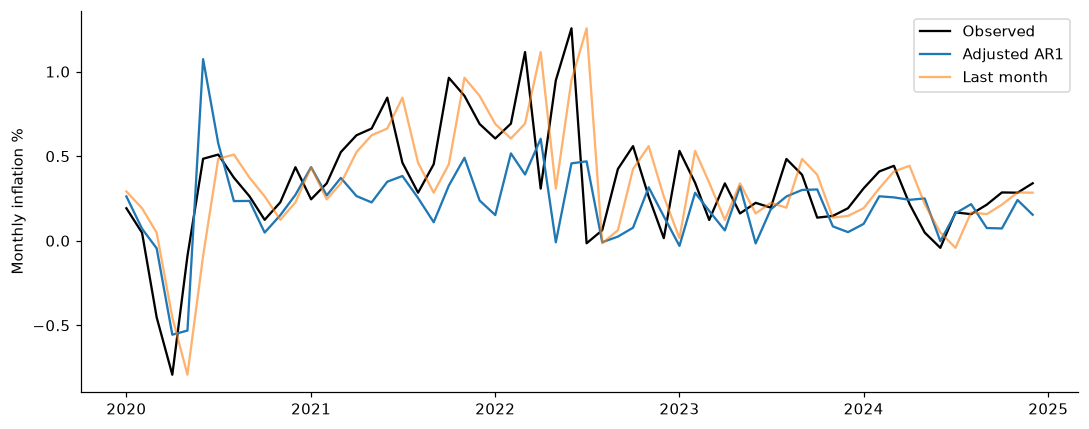

In [6]:
train=d[d.date<'2020-01-01'];test=d[d.date>='2020-01-01']
ct,act=sample_model(Xmat(train),train.monthly.to_numpy(),seed=122)
dt=diagnostics(ct,['alpha','beta','gamma','sigma','phi']);dt.to_csv(OUT/'training_diagnostics.csv',index=False)
print('Training-model diagnostics:');print(dt.round(4).to_string(index=False))
bt=ct.reshape(-1,5).mean(axis=0);allmu=Xmat(d)@bt[:3];allr=d.monthly.to_numpy()-allmu
conditional=allmu[240:]+bt[4]*allr[239:-1]
preds={'training mean':np.repeat(train.monthly.mean(),60),'last-month inflation':test.last_monthly.to_numpy(),'Bayesian adjusted AR1':conditional}
f=sm.OLS(train.monthly,Xmat(train)).fit();preds['adjusted independent errors']=Xmat(test)@np.asarray(f.params)
metrics=[]
for label,pred in preds.items():
    err=test.monthly.to_numpy()-pred;metrics.append({'model':label,'test_n':60,'MAE':np.abs(err).mean(),'RMSE':np.sqrt(np.mean(err**2))})
metrics=pd.DataFrame(metrics);print(metrics.round(4).to_string(index=False));metrics.to_csv(OUT/'holdout_metrics.csv',index=False)
plt.plot(test.date,test.monthly,color='black',label='Observed');plt.plot(test.date,conditional,label='Adjusted AR1');plt.plot(test.date,test.last_monthly,alpha=.6,label='Last month')
plt.ylabel('Monthly inflation %');plt.legend();plot_save('holdout_predictions')

## What these checks cannot establish
Good sampling or improved prediction does not prove causality. Oil prices contain supply and demand
movements. One lagged shipping-based proxy need not block global demand, expectations, supply-chain,
policy, exchange-rate, or other paths. A single country's time series has policy feedback and changing
regimes. Correlation strength neither proves nor disproves confounding. This exploratory comparison
does not turn adjustment into an identified causal effect, and outcome/model revisions used the same
historical data. Do not call the 2020–2024 period an untouched confirmatory holdout.

This notebook covers feasibility and model validation, not a submission-ready causal analysis. The
accompanying docs/PROJECT_PLAN.md gives the recommendation, exact scope, and course requirements.

## Independent implementation checks and additional dependence sensitivity
Cross-check the hand-written likelihood against a multivariate Normal AR(1) covariance, and
use ArviZ's built-in rank-based diagnostics. Additional AR orders below are frequentist sensitivity
checks, not a search that establishes a causal model or a substitute for Bayesian prior validation.

In [7]:
import arviz as az
from scipy.stats import multivariate_normal
from statsmodels.tsa.statespace.sarimax import SARIMAX
azdata=az.from_dict(posterior={name:chains[:,:,j] for j,name in enumerate(['alpha','beta','gamma','sigma','phi'])})
azsummary=az.summary(azdata,hdi_prob=.95,round_to=5)
print('ArviZ built-in diagnostics:');print(azsummary.to_string());azsummary.to_csv(OUT/'arviz_diagnostics.csv')
assert (azsummary.r_hat<1.01).all() and (azsummary.ess_bulk>400).all()
Xs=Xmat(d)[:12];ys=d.monthly.to_numpy()[:12];lp=target_factory(Xs,ys)
def independent_logp(z):
    b=z[:3];sig=np.exp(z[3]);phi=np.tanh(z[4]);i=np.arange(len(ys))
    cov=sig**2/(1-phi**2)*phi**np.abs(i[:,None]-i[None,:])
    return (multivariate_normal.logpdf(ys,mean=Xs@b,cov=cov)
            -.5*np.sum((b/np.array([.5,.3,.5]))**2)-.5*(sig/.5)**2+z[3]+np.log1p(-phi**2))
z1=np.array([.2,.1,.05,np.log(.25),np.arctanh(.3)])
z2=np.array([.1,.15,-.03,np.log(.4),np.arctanh(-.2)])
assert np.isclose(lp(z1)-lp(z2),independent_logp(z1)-independent_logp(z2),atol=1e-9)
print('AR1 likelihood and transformation Jacobians agree with independent covariance calculation.')
orders=[]
for order in [1,2,3]:
    r=SARIMAX(d.monthly,exog=d[['T','C']],trend='c',order=(order,0,0)).fit(disp=False)
    orders.append({'AR_order':order,'AIC':r.aic,'beta':r.params['T'],
                   'innovation_LB_p12':acorr_ljungbox(r.resid,lags=[12],return_df=True).lb_pvalue.iloc[0]})
orders=pd.DataFrame(orders);print(orders.round(5).to_string(index=False));orders.to_csv(OUT/'AR_order_sensitivity.csv',index=False)

ArviZ built-in diagnostics:
          mean       sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd    ess_bulk    ess_tail    r_hat
alpha  0.19924  0.02339   0.15203    0.24415    0.00050  0.00029  2197.31609  3617.23558  1.00090
beta   0.09448  0.01764   0.06073    0.12872    0.00037  0.00022  2301.08048  3550.76360  1.00201
gamma  0.04118  0.03297  -0.02143    0.10622    0.00071  0.00046  2170.08858  3230.86218  1.00152
sigma  0.25678  0.01066   0.23509    0.27735    0.00022  0.00013  2296.61540  3825.77057  1.00279
phi    0.34262  0.06573   0.21844    0.47859    0.00131  0.00083  2498.53208  3380.64616  1.00255
AR1 likelihood and transformation Jacobians agree with independent covariance calculation.


 AR_order      AIC    beta  innovation_LB_p12
        1 38.84440 0.09597            0.00271
        2 39.13163 0.08787            0.00607
        3 39.13286 0.08747            0.03660


## Working direction and findings
Proceed with the focused monthly US oil-inflation study. Keep the three substantive variables,
state the causal assumptions explicitly, and treat the current Gaussian AR(1) model as a baseline.
The next modeling step is to test Student-t innovations and repeat validation; that work is not complete.

- Adjusted oil association: **0.0945** monthly inflation percentage points per 10-percentage-point
  higher oil change, with model-conditional 95% equal-tailed credible interval **[0.0602, 0.1284]**.
- Unadjusted association: **0.0936**. The small change does not demonstrate sufficient causal adjustment.
- Simulation recovers **0.1498** for a true **0.1500**, validating computation under assumed conditions.
- Dependence remains (12-lag innovation diagnostic p around **0.0025**) and negative-tail prediction fails.
- Retrospective RMSE: **0.3221** for AR(1), **0.3158** for last-month inflation. Prediction is secondary.
- Built-in ArviZ diagnostics pass; this establishes sampling quality, not causal identification.

See [the project plan](../docs/PROJECT_PLAN.md) for scope and remaining work. The empirical result
supports a positive association; a causal interpretation depends on strong, unverified assumptions.